# 4 · Clustering movements by their time-normalised shape + length

1. Each IBL movement's 200 Hz velocity, **padded by 50 ms on each side** (IBL intervals often start after the movement begins or end before it stops), is **linearly time-normalised** to `NT` bins: one stretch factor per movement.
2. **Sign is kept** (wheel coordinates, + = one direction): a leftward and a rightward push are different shapes. Each movement is divided by its peak speed; vigor is kept as a readout, not a feature.
3. **PCA** on the pooled shapes; keep the PCs that explain 90 % of the variance.
4. Gaussian mixture on the standardised PC scores **plus log duration**. K fixed.

Data: 6 mice from 6 labs, first / middle / last training session each (18 sessions), pooled.

*Archived (2026-11-05): an approach that was not taken forward. Kept for reference; outputs are from the original run.*

In [1]:
import sys; sys.path.insert(0, '..')   # archived: the modules live one folder up
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import normalized_mutual_info_score as nmi
import wheel_states as ws, primitives as pr

MICE = ['CSHL049', 'UCLA017', 'ZFM-01592', 'NYU-11', 'SWC_043', 'ibl_witten_27']
NT, VAR, K = 200, 0.90, 20
PDIR = ws.DM_DIR.parent / 'wheel_primitives'
man = ws.manifest()

shapes, rows, SESS = [], [], {}
for mouse in MICE:
    m = man.query('mouse == @mouse').sort_values('session_index')
    for stage, (_, r) in zip(['first', 'middle', 'last'], m.iloc[[0, len(m) // 2, -1]].iterrows()):
        dm, tr = ws.load_session(r.eid, mouse)
        mv = pd.read_parquet(PDIR / f'movements_{r.eid}_{mouse}')
        t, v = dm.times.values, dm.velocity.values
        SESS[r.eid] = dict(t=t, v=v, tr=tr, mv=mv, mouse=mouse, stage=stage)
        for k, row in mv.iterrows():
            tt, vv = pr.movement_window(t, v, row.onset, row.offset)     # +-50 ms
            if len(vv) < 4:
                continue
            peak = np.abs(vv).max()
            shapes.append(np.interp(np.linspace(0, 1, NT), np.linspace(0, 1, len(vv)), vv) / peak)
            rows.append(dict(mouse=mouse, stage=stage, eid=r.eid, movement=k, onset=row.onset, offset=row.offset,
                             duration=row.offset - row.onset, peak=peak, n_prim=row.n_primitives,
                             epoch=pr.epoch_of(row.onset, tr)[0]))
S = np.array(shapes, np.float32); info = pd.DataFrame(rows)
print(len(info), 'movements'); print(info.groupby(['mouse', 'stage'], sort=False).size().unstack())

18255 movements
stage          first  middle  last
mouse                             
CSHL049          637    1834  1952
UCLA017          515     683  1387
ZFM-01592        798    1528  1900
NYU-11           298     301  1625
SWC_043          793     706  1423
ibl_witten_27    154     508  1213


## PCA of the signed shapes

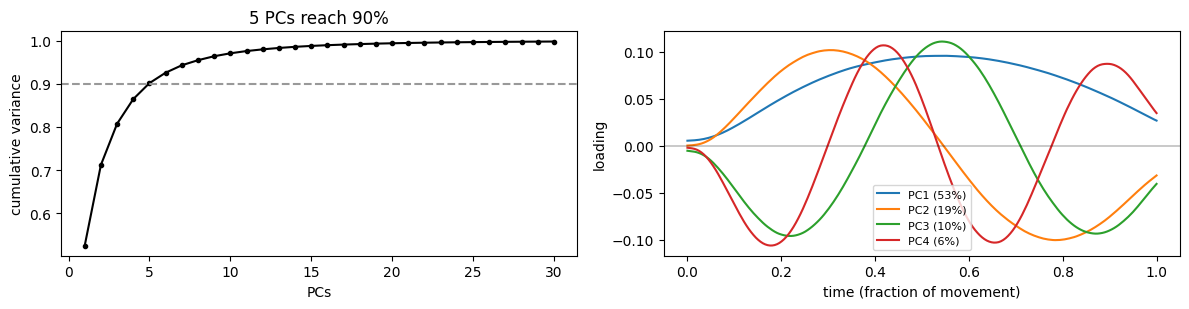

In [2]:
pca = PCA().fit(S)
n_pc = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), VAR) + 1)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
axs[0].plot(np.arange(1, 31), np.cumsum(pca.explained_variance_ratio_[:30]), 'o-', c='k', ms=3)
axs[0].axhline(VAR, c='0.6', ls='--'); axs[0].set(xlabel='PCs', ylabel='cumulative variance', title=f'{n_pc} PCs reach {VAR:.0%}')
x = np.linspace(0, 1, NT)
for i in range(4):
    axs[1].plot(x, pca.components_[i], label=f'PC{i + 1} ({pca.explained_variance_ratio_[i]:.0%})')
axs[1].axhline(0, c='k', lw=.3); axs[1].set(xlabel='time (fraction of movement)', ylabel='loading'); axs[1].legend(fontsize=8)
plt.tight_layout()

## Cluster on shape PCs + log duration

In [3]:
F = np.column_stack([pca.transform(S)[:, :n_pc], np.log10(info.duration)])
F = (F - F.mean(0)) / F.std(0)
gmm = GaussianMixture(K, covariance_type='full', n_init=5, random_state=0).fit(F)
lab = gmm.predict(F)
# order: by net direction of the median shape (leftward ... rightward), then duration
med = pd.DataFrame({'net': S.mean(1), 'dur': info.duration, 'lab': lab}).groupby('lab').median()
order = med.sort_values(['net']).index
info['cls'] = pd.Series(lab).map({c: i for i, c in enumerate(order)}).values
COL = plt.cm.tab20(np.arange(K) % 20)
print('NMI(cluster, mouse) =', round(nmi(info.mouse, info.cls), 3), '  NMI(cluster, stage) =', round(nmi(info.stage, info.cls), 3))
info.groupby('cls').agg(fraction=('cls', lambda c: len(c) / len(info)), duration_s=('duration', 'median'),
                        peak_rad_s=('peak', 'median'), n_prim=('n_prim', 'median'),
                        response=('epoch', lambda e: (e == 'response').mean()),
                        pre_stim=('epoch', lambda e: (e == 'pre-stim').mean())).round(2)

NMI(cluster, mouse) = 0.044   NMI(cluster, stage) = 0.02


,fraction,duration_s,peak_rad_s,n_prim,response,pre_stim
cls,,,,,,
0,0.02,0.11,0.56,2.0,0.34,0.19
1,0.03,0.18,1.40,1.0,0.59,0.15
2,0.03,0.34,2.35,1.0,0.70,0.14
3,0.04,0.15,0.90,1.0,0.47,0.19
4,0.05,0.46,3.00,2.0,0.51,0.26
5,0.03,0.28,3.05,2.0,0.67,0.16
6,0.04,0.43,2.62,3.0,0.59,0.21
7,0.07,0.41,1.57,2.0,0.53,0.18
8,0.03,0.98,3.41,3.0,0.55,0.23


### Each cluster: 60 random members (thin) and median (thick); x = fraction of the movement, + = one wheel direction

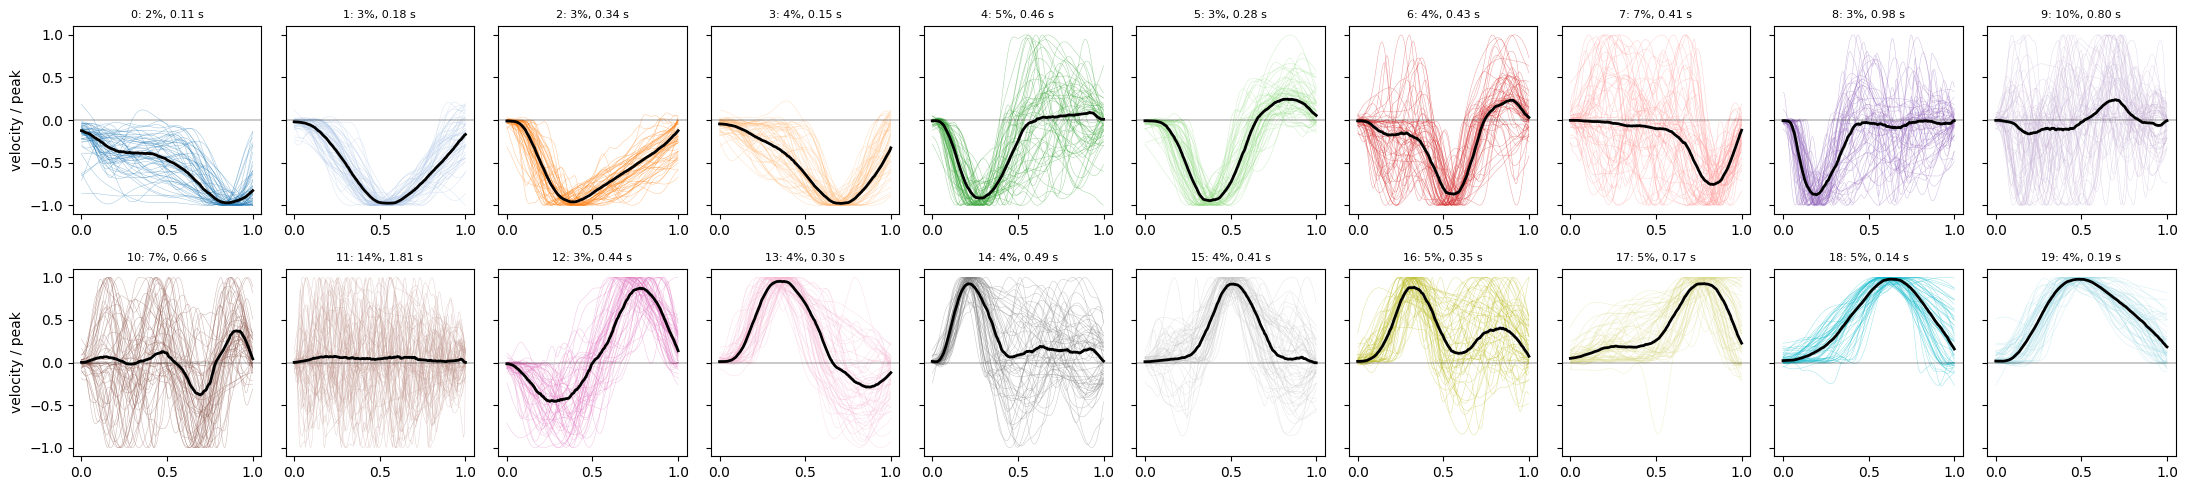

In [4]:
fig, axs = plt.subplots(2, K // 2, figsize=(2.2 * K / 2, 5), sharey=True)
rng = np.random.default_rng(0)
for c, ax in enumerate(axs.flat):
    a = S[info.cls == c]
    ax.plot(x, a[rng.choice(len(a), min(60, len(a)), replace=False)].T, c=COL[c], lw=.3, alpha=.5)
    ax.plot(x, np.median(a, 0), c='k', lw=2); ax.axhline(0, c='k', lw=.3)
    ax.set_title(f'{c}: {len(a) / len(S):.0%}, {info.duration[info.cls == c].median():.2f} s', fontsize=8)
for ax in axs[:, 0]: ax.set_ylabel('velocity / peak')
plt.tight_layout()

### Each cluster in real time: random members from any session, rad/s, x = seconds from onset

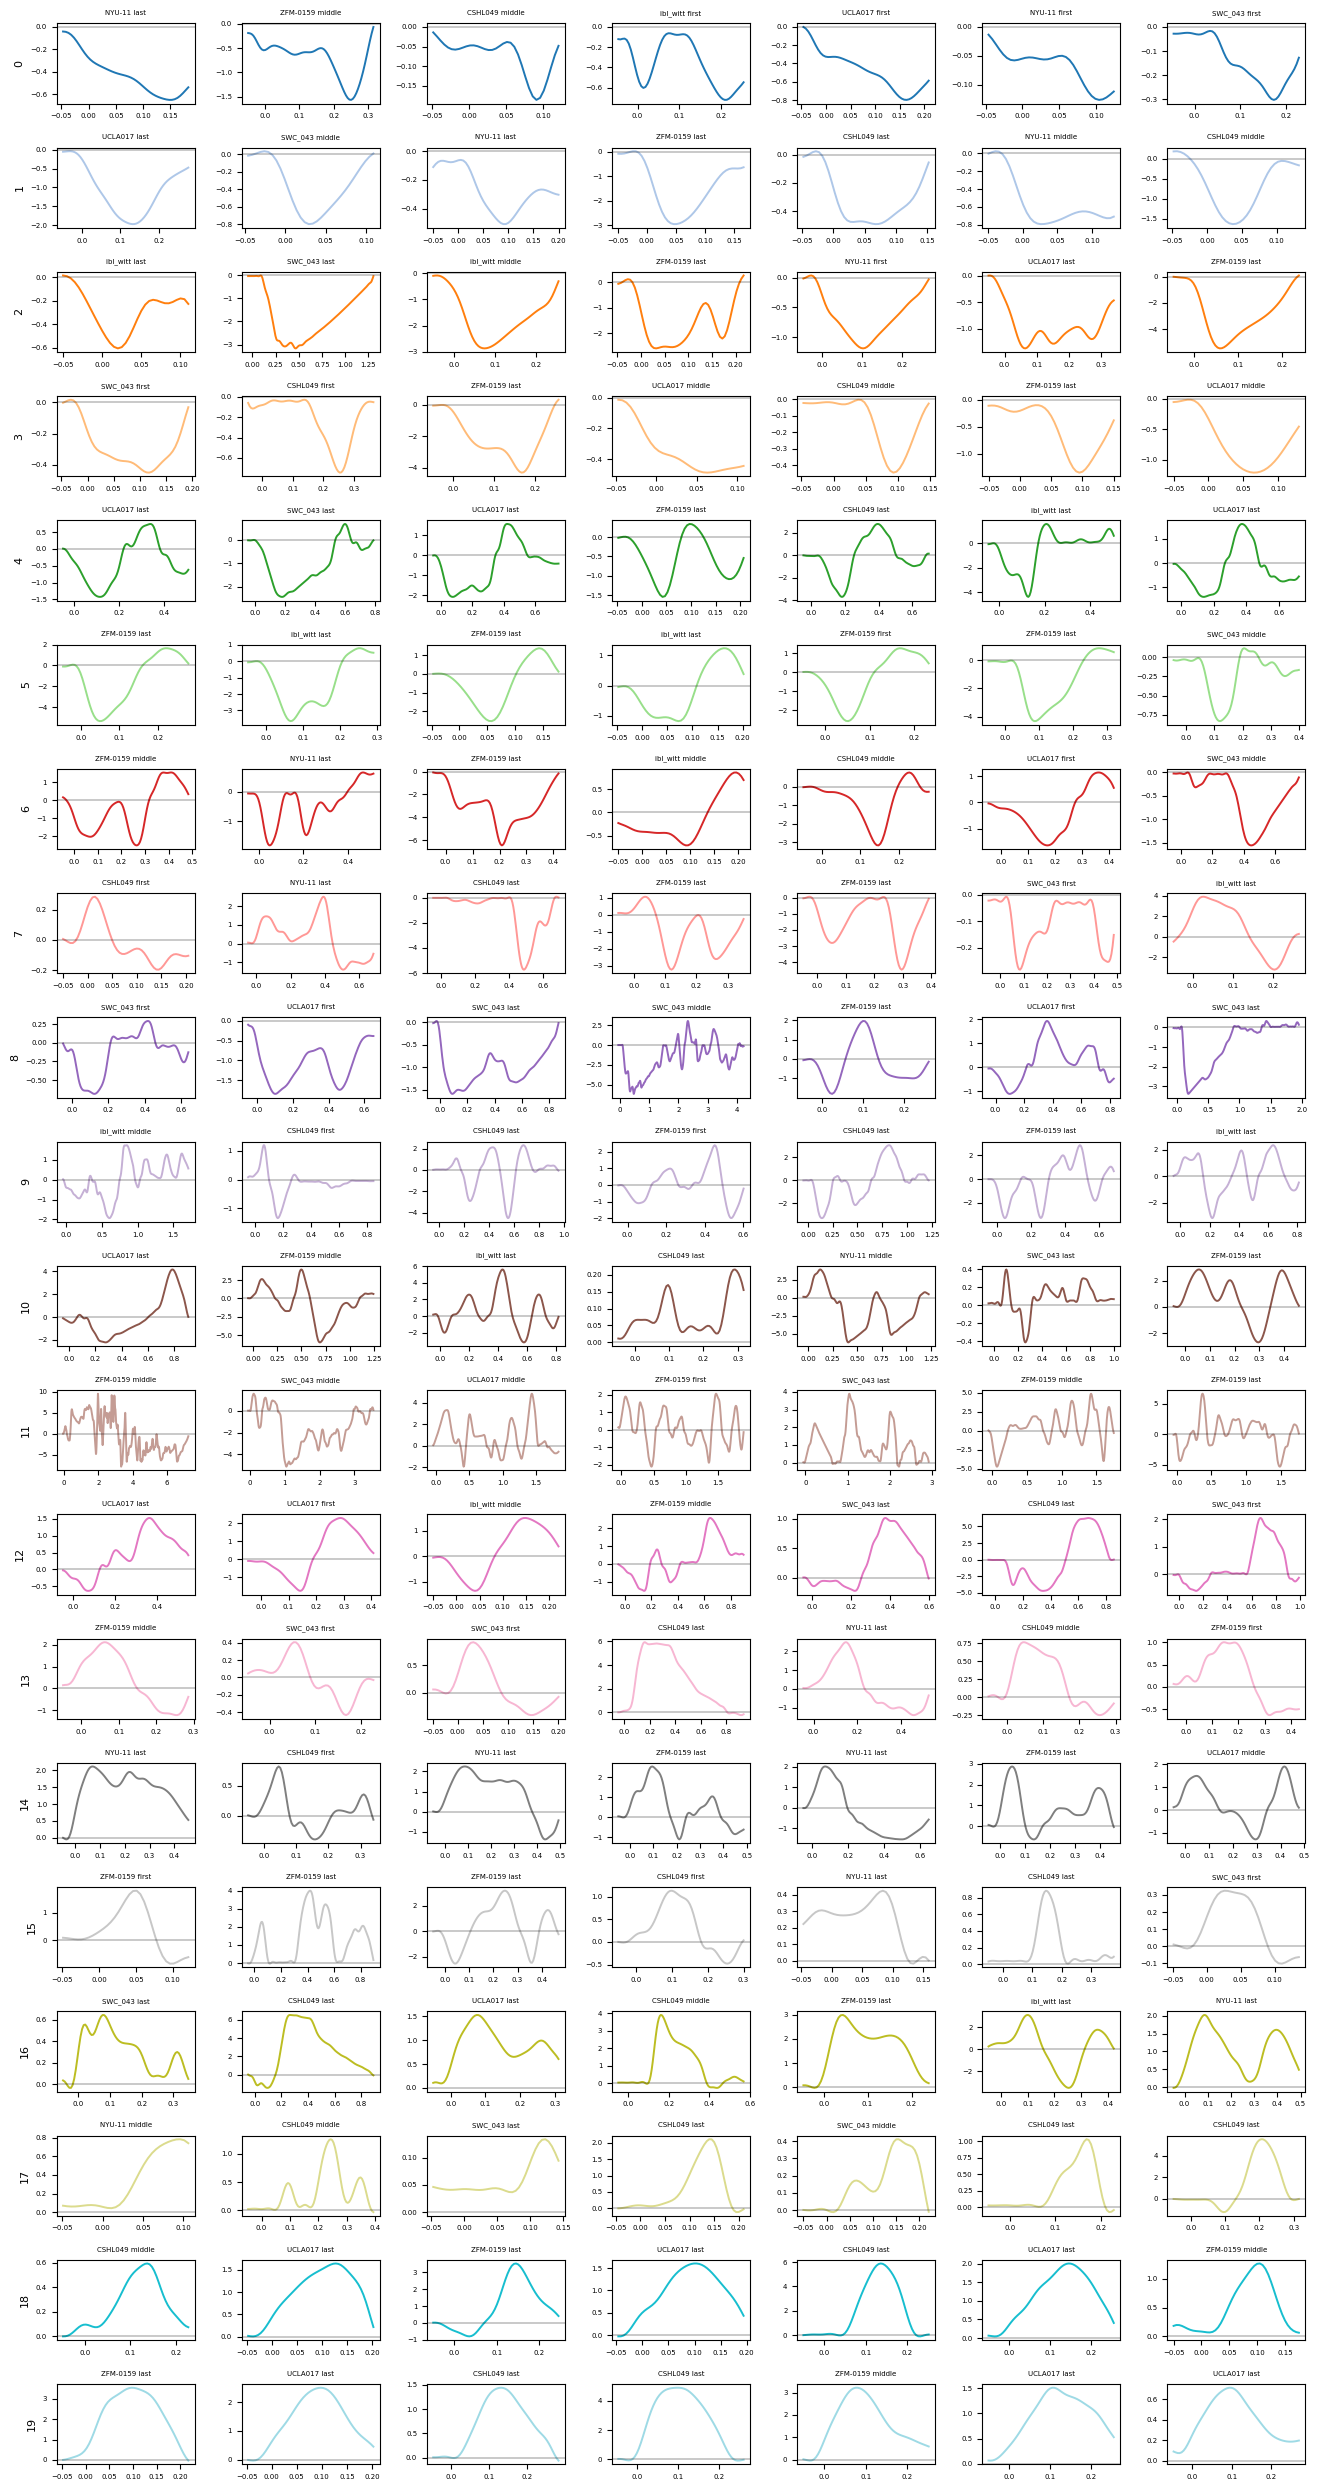

In [5]:
N_EX = 7
fig, axs = plt.subplots(K, N_EX, figsize=(1.9 * N_EX, 1.25 * K), squeeze=False)
rng = np.random.default_rng(1)
for c in range(K):
    for j, i in enumerate(rng.choice(info.index[info.cls == c], min(N_EX, (info.cls == c).sum()), replace=False)):
        q = info.loc[i]; s = SESS[q.eid]; ax = axs[c, j]
        tt, vv = pr.movement_window(s['t'], s['v'], q.onset, q.offset)
        ax.plot(tt, vv, c=COL[c], lw=1.4); ax.axhline(0, c='k', lw=.3); ax.tick_params(labelsize=5)
        ax.set_title(f'{q.mouse[:8]} {q.stage}', fontsize=5)
    axs[c, 0].set_ylabel(f'{c}', fontsize=8)
plt.tight_layout()

## Are clusters shared across mice? How does use change over training?

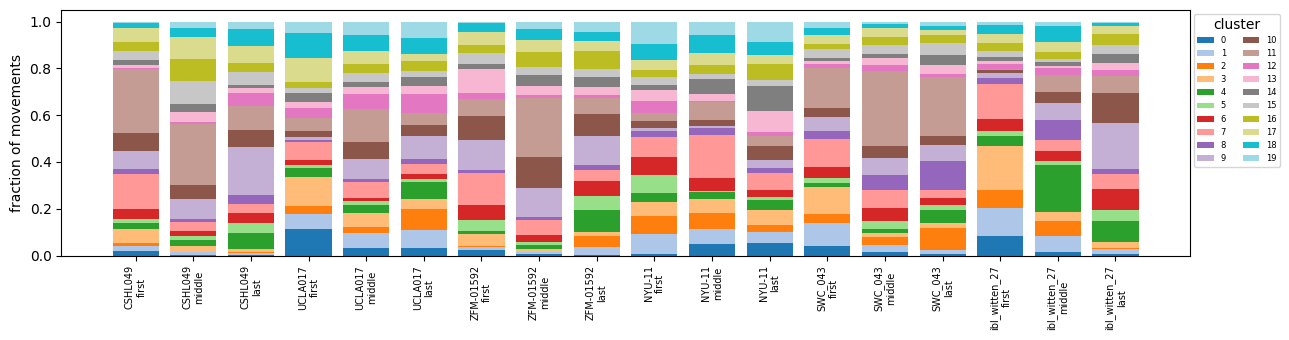

In [6]:
u = info.groupby(['mouse', 'stage'], sort=False).cls.value_counts(normalize=True).unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(13, 3.5))
bottom = np.zeros(len(u))
for c in range(K):
    ax.bar(range(len(u)), u[c], bottom=bottom, color=COL[c], label=str(c)); bottom += u[c].values
ax.set_xticks(range(len(u)), [f'{m}\n{s}' for m, s in u.index], fontsize=7, rotation=90)
ax.set(ylabel='fraction of movements'); ax.legend(fontsize=6, ncol=2, bbox_to_anchor=(1, 1), loc='upper left', title='cluster')
plt.tight_layout()

### The clusters in time: 25 s from several sessions (shading = cluster, number above; dashed blue = stimulus, red = feedback)

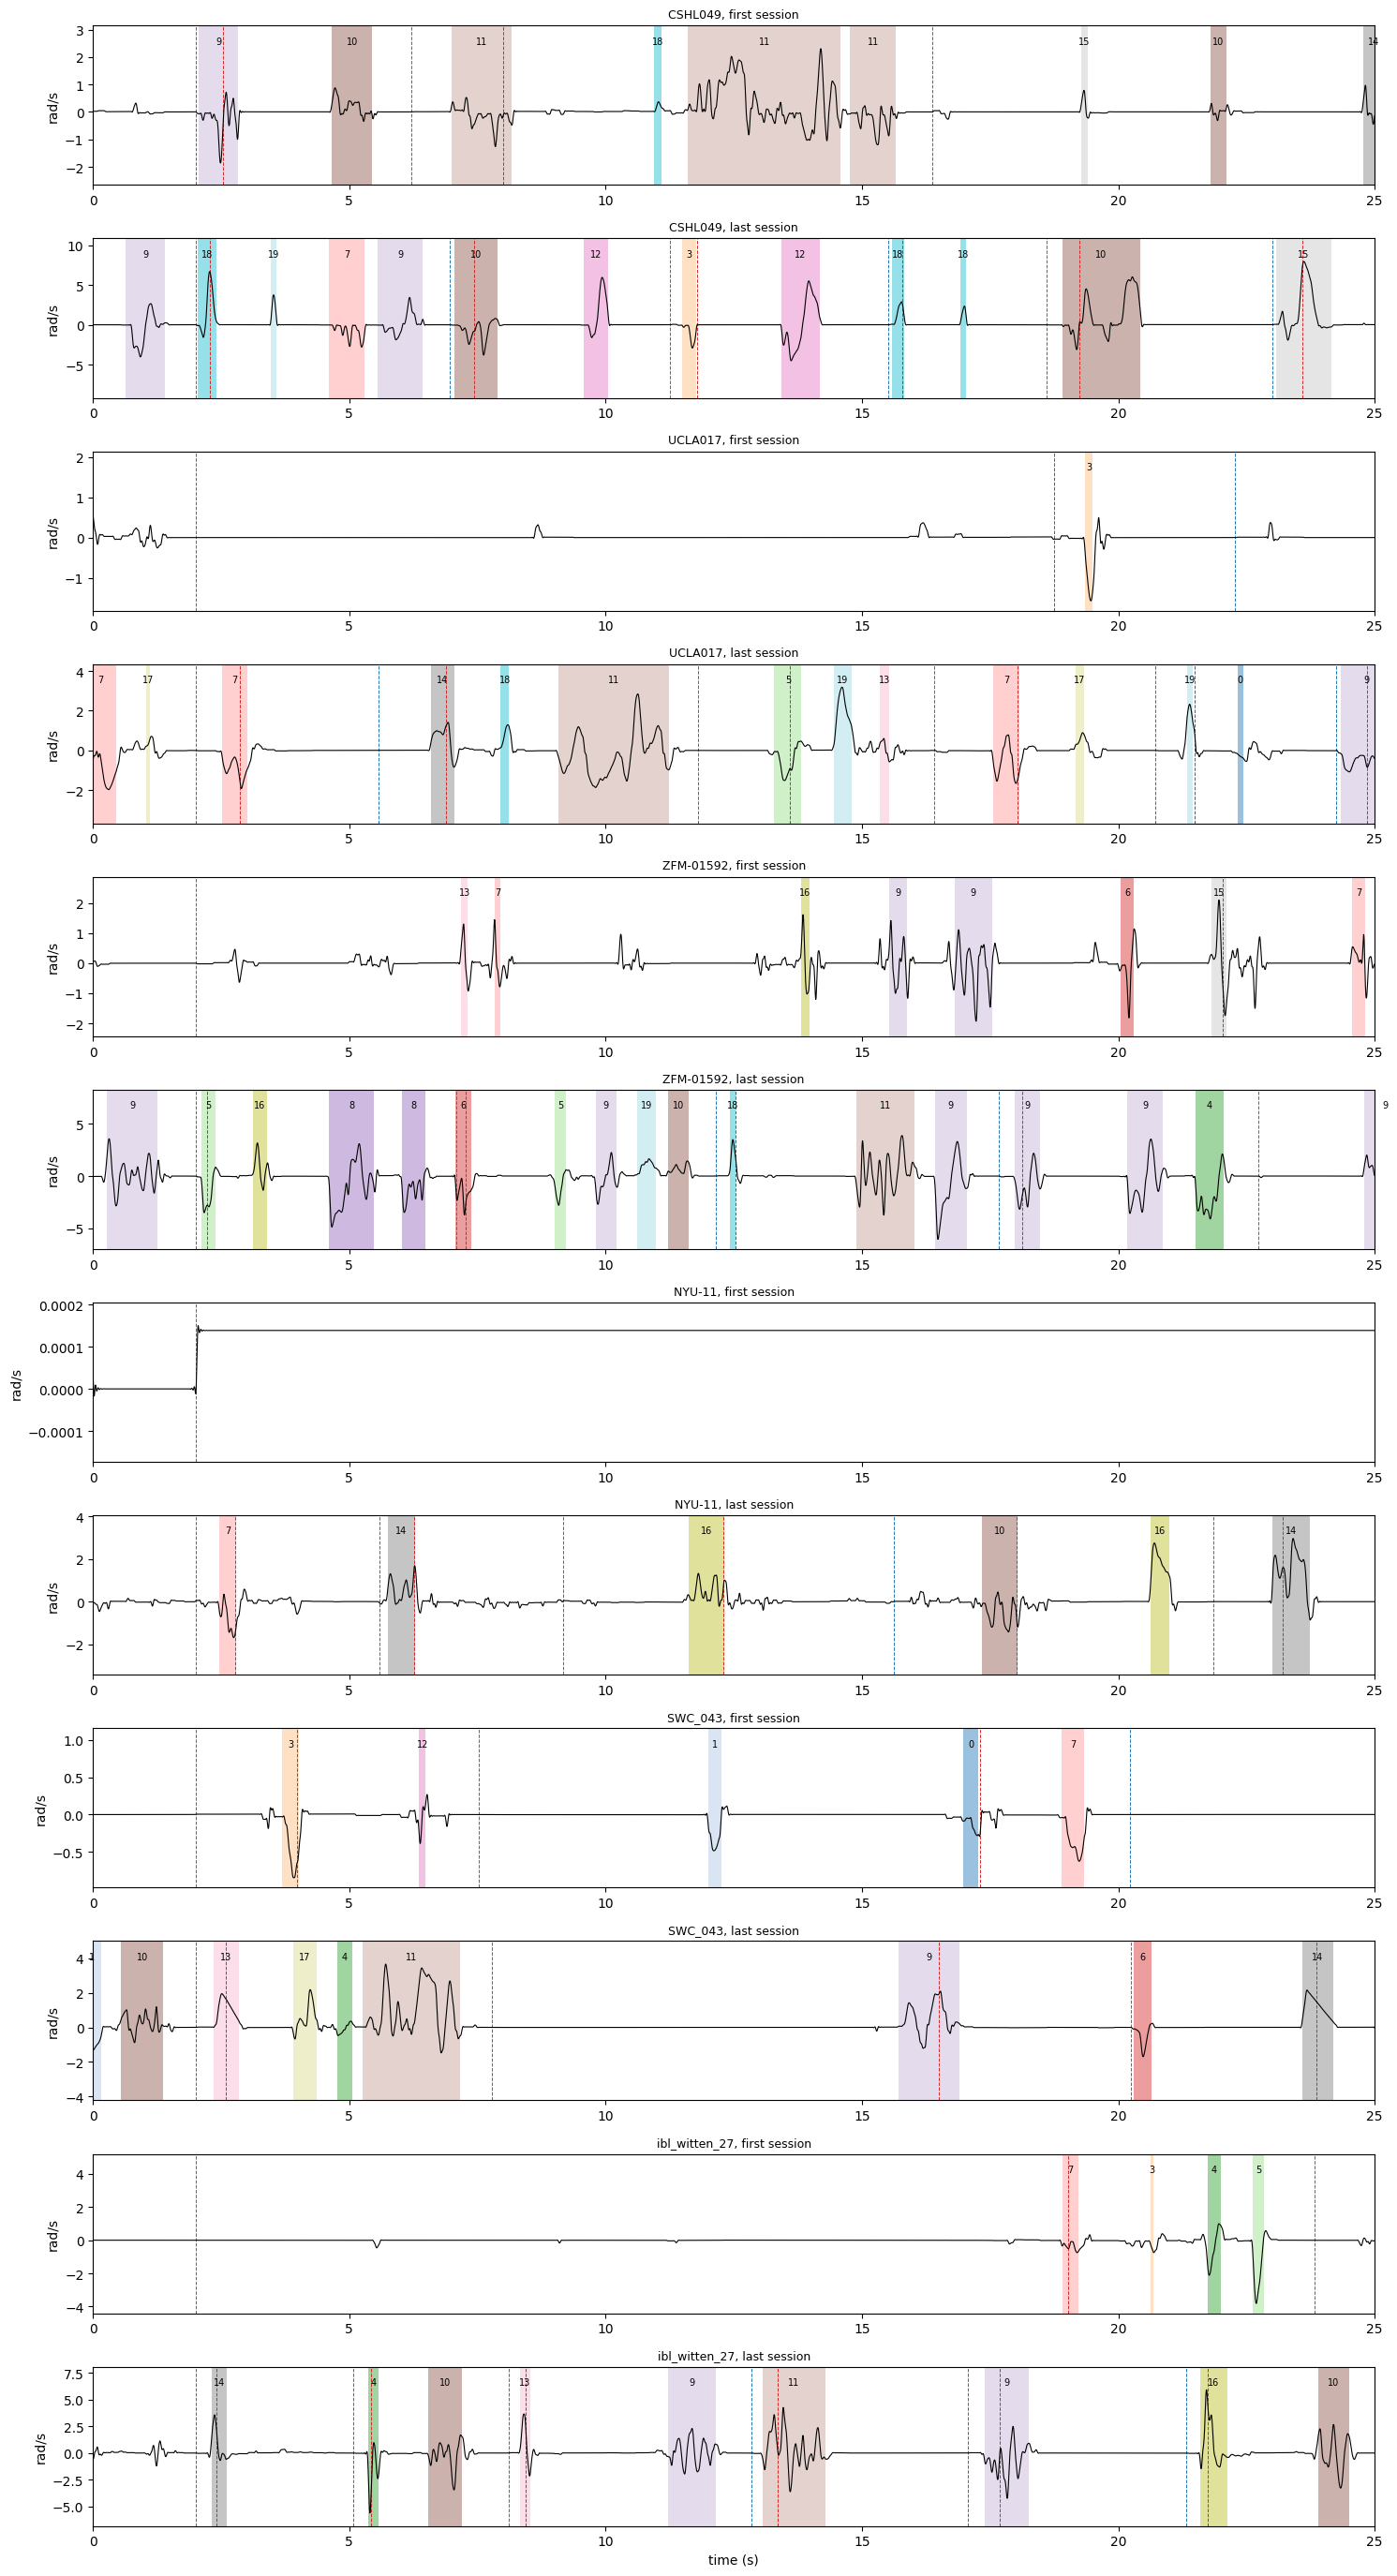

In [7]:
def timeline(eid, ax, frac=.4, win=25):
    s = SESS[eid]; t, v, tr = s['t'], s['v'], s['tr']
    stim = pr.stim_times(tr)
    t0 = stim.iloc[int(frac * len(tr))] - 2
    sel = (t > t0) & (t < t0 + win)
    ax.plot(t[sel] - t0, v[sel], c='k', lw=.8, zorder=3)
    top = np.abs(v[sel]).max() * 1.05
    for _, q in info[(info.eid == eid) & (info.offset > t0) & (info.onset < t0 + win)].iterrows():
        ax.axvspan(q.onset - t0, q.offset - t0, color=COL[q.cls], alpha=.45, lw=0)
        ax.text((q.onset + q.offset) / 2 - t0, top, str(q.cls), ha='center', va='bottom', fontsize=7)
    for e, c in [(stim.values, 'tab:blue'), (tr.feedback_times.values, 'tab:red')]:
        for x_ in e:
            if 0 < x_ - t0 < win: ax.axvline(x_ - t0, c=c, ls='--', lw=.7)
    ax.set(xlim=(0, win), ylim=(-top * 1.1, top * 1.3), ylabel='rad/s')
    ax.set_title(f"{s['mouse']}, {s['stage']} session", fontsize=9)

show = [e for e, s in SESS.items() if s['stage'] in ('first', 'last')]
fig, axs = plt.subplots(len(show), 1, figsize=(15, 2.3 * len(show)))
for ax, e in zip(axs, show):
    timeline(e, ax)
axs[-1].set_xlabel('time (s)')
plt.tight_layout()